# NB11 — Pico Sweep: Frequency-Domain Sensor Characterisation

**Version:** 2
**Author:** CB

---

## 1  Objective

Characterise both AE sensor channels (CH3, CH4) over 5–100 kHz using a Pico-controlled
frequency sweep.  The following metrics are computed at each drive frequency $f_0$:

| Symbol | Metric | Unit |
|---|---|---|
| $\hat{A}_k(f_0)$ | Amplitude at $f_0$ | mV |
| $\text{SNR}_k(f_0)$ | Signal-to-noise ratio | — |
| $\hat{\gamma}^2(f_0)$ | Multi-frame spectral coherence CH3–CH4 (Welch) | [0, 1] |
| $\text{THD}_k(f_0)$ | Total harmonic distortion (SNR ≥ 3 only) | % |
| $\hat{\tau}_{34}^{\text{MLE}}(f_0)$ | MLE time-delay estimate CH3→CH4 | µs |
| $\delta f_k(f_0)$ | FFT-peak deviation from $f_0$ | Hz |
| $\text{CV}_k(f_0)$ | Amplitude repeatability (coeff. of variation) | % |

---

## 2  Instrumentation & Setup

| Item | Specification |
|---|---|
| Signal generator | Raspberry Pi Pico (RP2040), firmware `pico_rust_sweep`, GP15 → piezo actuator |
| Waveform | Square wave; mechanical low-pass of steel rod approximates sinusoidal excitation |
| Sweep | Linear, $f_\text{start}$=5 kHz, $f_\text{stop}$=100 kHz, step=5 kHz, 20 bands, 1.5 s/band |
| Trigger marker | GP14 → Rigol CH1, rising edge, 500 µs pulse per band transition |
| Oscilloscope | Rigol DS1104Z, NORM mode, ~1 MSa/s, 1 200 pts/channel |
| CH1 | Trigger input (DC, 1 V/div, ×1 probe) — *waveform not read* |
| CH3, CH4 | AE sensors, amplified, AC coupling, 0.5 V/div, ×10 probe |
| Trigger | CH1, positive edge, 0.5 V, NORM sweep |
| Discharge resistor | $R_d$ = 820 kΩ ∥ each piezo; $f_\text{HP} = (2\pi R_d C_p)^{-1} \approx 970\,\text{Hz}$ for $C_p$=200 pF (negligible above 5 kHz) |

---

## 3  Signal Processing

### 3.1  Windowed DFT and amplitude normalisation

$$V_k^{(i)}[m] = \sum_{n=0}^{N-1} v_k^{(i)}[n]\,w[n]\,e^{-j2\pi mn/N}, \quad w[n]=\tfrac{1}{2}\!\left(1-\cos\tfrac{2\pi n}{N-1}\right)$$

One-sided peak-normalised amplitude: $A_k^{(i)}[m] = 2|V_k^{(i)}[m]|\,/\!\sum_n w[n]$

Frequency resolution: $\Delta f = f_s / N$

### 3.2  SNR

Off-band noise mean (excluding DC and ±10 % of $f_0$):

$$\text{SNR}_k^{(i)} = \hat{A}_k^{(i)} \;/\; \bar{A}_{k,\text{off}}^{(i)}$$

### 3.3  Multi-frame coherence (Welch estimator)

Accumulated over $N_b$ frames captured at band $f_0$:

$$\hat{\gamma}^2(f_0) = \frac{\left|\sum_i V_3^{(i)}[m_0]\,\overline{V_4^{(i)}[m_0]}\right|^2}{\left(\sum_i |V_3^{(i)}[m_0]|^2\right)\!\left(\sum_i |V_4^{(i)}[m_0]|^2\right)}$$

For $N_b=1$ this equals 1 identically; values below 0.9 indicate incoherent noise.

### 3.4  THD

$$\text{THD}_k(f_0)=\frac{\sqrt{\sum_{h=2}^{H}\hat{A}_k^2(h f_0)}}{\hat{A}_k(f_0)}, \quad H=\max\{h:h f_0<0.95\,f_s/2\}$$

Only reported when $\text{SNR}_k \ge 3$; values >100 % indicate harmonic contamination exceeds the fundamental.

### 3.5  MLE time-delay estimate

$$\hat{\tau}_{34}(f_0)=-\frac{\angle\!\left[\sum_i V_3^{(i)}[m_0]\,\overline{V_4^{(i)}[m_0]}\right]}{2\pi f_0}$$

Phase wrapped to $(-\pi,\pi]$; results with $|\hat{\tau}|>1/(2f_0)$ indicate phase ambiguity.

---

In [1]:
# §4  Dependencies & Configuration
%matplotlib inline
import sys, time, json
from pathlib import Path
from datetime import datetime, timezone
from collections import defaultdict

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

sys.path.insert(0, '..')
sys.path.insert(0, '../instrument_control')
from scope.config import load_config
from scope.instrument import InstrumentConnection, parse_preamble
from plant_ae.watering import CONFIG_PATH

# ── Acquisition parameters ──────────────────────────────────────────────────
BANDS_HZ   = list(range(5_000, 101_000, 5_000))  # 20 drive frequencies [Hz]
N_BANDS    = len(BANDS_HZ)
N_CAPTURES = 80        # target captures (~4 sweeps; ≥3 frames/band for coherence)
TIM_SCAL   = 1e-4     # s/div  →  1.2 ms window, f_s ≈ 1 MSa/s
FS_MIN     = 900_000  # Hz  — reject captures below this sample rate
TRIG_WAIT  = 3.5      # s   — trigger timeout per capture
SKIP_S     = 0.10     # s   — post-SING settling delay
BAND_DT    = 1.5      # s   — nominal inter-trigger interval
CH_TRIG    = 1        # trigger channel (not read)
CH_AE      = (3, 4)   # AE sensor channels

config = load_config(CONFIG_PATH)
print('Configuration loaded.')
print(f'  Bands   : {BANDS_HZ[0]/1e3:.0f}–{BANDS_HZ[-1]/1e3:.0f} kHz, '
      f'step {(BANDS_HZ[1]-BANDS_HZ[0])/1e3:.0f} kHz, {N_BANDS} bands')
print(f'  Captures: {N_CAPTURES}  (~{N_CAPTURES/N_BANDS:.1f} frames/band)')


Configuration loaded.
  Bands   : 5–100 kHz, step 5 kHz, 20 bands
  Captures: 80  (~4.0 frames/band)


In [2]:
# §4.1  Scope configuration
def configure_scope(conn):
    conn.write(':STOP')
    for cmd in [':CHAN1:DISP ON', ':CHAN1:COUP DC',
                ':CHAN1:SCAL 1.0', ':CHAN1:PROB 1', ':CHAN1:OFFS 0']:
        conn.write(cmd)
    conn.write(':CHAN2:DISP OFF')
    for ch in CH_AE:
        for cmd in [f':CHAN{ch}:DISP ON', f':CHAN{ch}:COUP AC',
                    f':CHAN{ch}:SCAL 0.5', f':CHAN{ch}:PROB 10',
                    f':CHAN{ch}:OFFS 0']:
            conn.write(cmd)
    conn.write(f':TIM:SCAL {TIM_SCAL}')
    conn.write(':TIM:OFFS 0')
    conn.write(':ACQ:TYPE NORM')
    conn.write(':ACQ:MDEP AUTO')
    conn.write(':TRIG:MODE EDGE')
    conn.write(f':TRIG:EDGE:SOUR CHAN{CH_TRIG}')
    conn.write(':TRIG:EDGE:SLOP POS')
    conn.write(':TRIG:EDGE:LEV 0.5')
    conn.write(':TRIG:SWE NORM')

print('configure_scope() defined.')


configure_scope() defined.


In [3]:
# §4.2  Per-frame metric computation
def per_frame_metrics(v3, v4, fs, band_hz):
    """
    Compute single-frame spectral metrics (see §3).

    Parameters
    ----------
    v3, v4  : ndarray  Voltage time series [V]
    fs      : float    Sample rate [Hz]
    band_hz : int      Drive frequency f0 [Hz]

    Returns
    -------
    dict — per-frame scalars + complex DFT bins at m0 for accumulation
    """
    N = min(len(v3), len(v4))
    v3, v4 = v3[:N], v4[:N]
    win  = np.hanning(N)
    norm = win.sum()
    freq = np.fft.rfftfreq(N, 1.0 / fs)

    V3 = np.fft.rfft(v3 * win)
    V4 = np.fft.rfft(v4 * win)
    A3 = 2 * np.abs(V3) / norm
    A4 = 2 * np.abs(V4) / norm

    m0 = int(round(band_hz * N / fs))
    m0 = max(2, min(m0, len(A3) - 3))

    def peak_amp(A, mc, hw=2):
        return float(A[max(0, mc-hw): mc+hw+1].max())

    amp3 = peak_amp(A3, m0)
    amp4 = peak_amp(A4, m0)

    bw = max(3, int(0.10 * m0))
    off = np.ones(len(A3), bool)
    off[max(0, m0-bw): m0+bw+1] = False
    off[:2] = False
    noise3 = float(A3[off].mean()) if off.any() else 1e-12
    noise4 = float(A4[off].mean()) if off.any() else 1e-12
    snr3 = amp3 / (noise3 + 1e-12)
    snr4 = amp4 / (noise4 + 1e-12)

    def thd(A, snr):
        if snr < 3.0:
            return float('nan')
        fund = peak_amp(A, m0)
        if fund < 1e-12:
            return float('nan')
        h_pwr = 0.0
        for h in range(2, 6):
            if h * band_hz > 0.95 * fs / 2:
                break
            mh = max(0, min(int(round(h * band_hz * N / fs)), len(A)-1))
            h_pwr += peak_amp(A, mh) ** 2
        return float(np.sqrt(h_pwr) / fund)

    def peak_freq(A):
        roi = (freq >= 0.8*band_hz) & (freq <= 1.2*band_hz)
        return float(freq[roi][np.argmax(A[roi])]) if roi.any() else float('nan')

    def crest(v):
        rms = np.sqrt(np.mean(v**2))
        return float(np.max(np.abs(v)) / (rms + 1e-12))

    return dict(
        amp3=amp3, amp4=amp4,
        snr3=snr3, snr4=snr4,
        thd3=thd(A3, snr3), thd4=thd(A4, snr4),
        peak_f3=peak_freq(A3), peak_f4=peak_freq(A4),
        cf3=crest(v3), cf4=crest(v4),
        V3_bin=complex(V3[m0]),
        V4_bin=complex(V4[m0]),
        fs=float(fs), N=int(N),
    )

print('per_frame_metrics() defined.')


per_frame_metrics() defined.


## 5  Data Acquisition

Each capture: arm scope (`:SING`) → poll `:TRIG:STAT?` → read CH3/CH4 NORM waveforms →
assign band via cyclic index (FFT-synchronised) → compute metrics → append to `records.jsonl`.

Complex DFT bins $V_k^{(i)}[m_0]$ are retained in memory for the Welch coherence and MLE TDE estimators.


In [4]:
RUN_TS    = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')
RUN_LOCAL = datetime.now().strftime('%Y%m%d_%H%M%S')
OUT       = Path('..') / 'data' / 'pico_sweep_calibration' / RUN_LOCAL
OUT.mkdir(parents=True, exist_ok=True)

# Accumulators for multi-frame Welch estimators
G34      = defaultdict(complex)   # cross-spectrum  Σ V3·V4*
G33      = defaultdict(float)     # auto-spectrum   Σ |V3|²
G44      = defaultdict(float)     # auto-spectrum   Σ |V4|²
N_frames = defaultdict(int)

records = []
meta = {
    'run_id': RUN_LOCAL, 'utc_start': RUN_TS,
    'bands_hz': BANDS_HZ, 'n_captures_target': N_CAPTURES,
    'tim_scal_s': TIM_SCAL, 'fs_min_hz': FS_MIN,
    'ch3': {'scal_V': 0.5, 'prob': 10, 'coup': 'AC'},
    'ch4': {'scal_V': 0.5, 'prob': 10, 'coup': 'AC'},
    'trig_ch': CH_TRIG, 'trig_lev_V': 0.5, 'trig_edge': 'POS',
    'discharge_R_ohm': 820_000, 'band_dt_s': BAND_DT,
}
with open(OUT / 'meta.json', 'w') as f:
    json.dump(meta, f, indent=2)

print(f'Run ID   : {RUN_LOCAL}')
print(f'UTC start: {RUN_TS}')
print(f'Output   : {OUT}')

with InstrumentConnection(config) as conn:
    configure_scope(conn); time.sleep(0.3)
    print(f'Scope configured. Starting {N_CAPTURES} captures ...')

    band_start_idx = None
    t_prev = None
    capture_n = frame_abs = n_recfg = n_timeout = 0

    while capture_n < N_CAPTURES:
        conn.write(f':TIM:SCAL {TIM_SCAL}')
        conn.write(':SING')
        time.sleep(SKIP_S)

        t0 = time.monotonic(); triggered = False
        while time.monotonic() - t0 < TRIG_WAIT:
            if conn.query(':TRIG:STAT?').strip().upper() == 'STOP':
                triggered = True; break
            time.sleep(0.008)
        t_trig = time.monotonic()

        if not triggered:
            n_timeout += 1
            print(f'  [C{capture_n+1:3d}] timeout — reconfiguring')
            configure_scope(conn); n_recfg += 1
            capture_n += 1; continue

        if t_prev is not None:
            dt = t_trig - t_prev
            missed = max(0, round(dt / BAND_DT) - 1)
            if missed:
                frame_abs += missed
                print(f'  [---] {missed} band(s) skipped  Δt={dt:.2f} s')
        t_prev = t_trig
        time.sleep(0.03)

        ch_data = {}; ok = True
        for ch in CH_AE:
            try:
                conn.write(f':WAV:SOUR CHAN{ch}')
                conn.write(':WAV:MODE NORM'); conn.write(':WAV:FORM BYTE')
                pre = parse_preamble(conn.query(':WAV:PRE?'))
                raw = conn.query_binary_values(':WAV:DATA?', datatype='B',
                                               is_big_endian=False)
            except Exception as exc:
                print(f'  VISA error CH{ch}: {exc}'); ok = False; break
            if len(raw) < 100 or pre.xincrement == 0:
                ok = False; break
            fs_act = 1.0 / pre.xincrement
            if fs_act < FS_MIN:
                print(f'  CH{ch}: f_s={fs_act/1e3:.0f} kSa/s < min — reconfiguring')
                configure_scope(conn); n_recfg += 1; ok = False; break
            v = ((np.array(raw, dtype=np.float32)
                  - pre.yorigin - pre.yreference) * pre.yincrement)
            ch_data[ch] = dict(v=v, fs=fs_act)

        if not ok:
            capture_n += 1; frame_abs += 1; continue

        l3, l4 = len(ch_data[3]['v']), len(ch_data[4]['v'])
        if abs(l3 - l4) > 0.5 * max(l3, l4):
            print(f'  Length mismatch CH3={l3} CH4={l4} — skip')
            capture_n += 1; frame_abs += 1; continue

        v3, v4 = ch_data[3]['v'], ch_data[4]['v']
        fs = ch_data[4]['fs']

        # Band synchronisation via FFT on CH4 (f0 > 12 kHz avoids steel eigenmode at ~9.17 kHz)
        if band_start_idx is None:
            N_t = min(len(v4), len(v3))
            w_t = np.hanning(N_t)
            A4t = 2*np.abs(np.fft.rfft(v4[:N_t]*w_t))/w_t.sum()
            fq  = np.fft.rfftfreq(N_t, 1.0/fs)
            roi = (fq > 12_000) & (fq < 105_000)
            if roi.any():
                base = np.median(A4t[roi])
                bb, bsnr = None, 0.0
                for b in BANDS_HZ:
                    if b < 12_000: continue
                    mi = int(round(b*N_t/fs))
                    a  = A4t[max(0,mi-2):mi+3].max()
                    if a/(base+1e-12) > bsnr:
                        bsnr = a/(base+1e-12); bb = b
                if bb and bsnr > 4.0:
                    band_start_idx = (BANDS_HZ.index(bb) - frame_abs) % N_BANDS
                    print(f'  Band sync: C{capture_n+1}/frame{frame_abs} → '
                          f'{bb/1e3:.0f} kHz (SNR={bsnr:.1f})')

        cyc_idx = (frame_abs + (band_start_idx or 0)) % N_BANDS
        band_hz = BANDS_HZ[cyc_idx]

        m = per_frame_metrics(v3, v4, fs, band_hz)

        # Accumulate cross-spectrum
        G34[band_hz] += m['V3_bin'] * m['V4_bin'].conjugate()
        G33[band_hz] += abs(m['V3_bin'])**2
        G44[band_hz] += abs(m['V4_bin'])**2
        N_frames[band_hz] += 1

        rec = {
            'capture': capture_n+1, 'frame_abs': frame_abs,
            'ts_utc': datetime.now(timezone.utc).isoformat(),
            'band_hz': int(band_hz),
            'amp3_V': round(float(m['amp3']), 8),
            'amp4_V': round(float(m['amp4']), 8),
            'snr3':   round(float(m['snr3']), 3),
            'snr4':   round(float(m['snr4']), 3),
            'thd3': None if (v:=m['thd3']) != v else round(float(v),4),
            'thd4': None if (v:=m['thd4']) != v else round(float(v),4),
            'peak_f3_hz': round(float(m['peak_f3']),1) if m['peak_f3']==m['peak_f3'] else None,
            'peak_f4_hz': round(float(m['peak_f4']),1) if m['peak_f4']==m['peak_f4'] else None,
            'cf3': round(float(m['cf3']),3), 'cf4': round(float(m['cf4']),3),
            'fs_hz': round(float(m['fs']),0), 'n_pts': int(m['N']),
        }
        records.append(rec)
        with open(OUT / 'records.jsonl', 'a') as fh:
            fh.write(json.dumps(rec) + '\n')

        t4s = f"{m['thd4']*100:.0f}%" if m['thd4']==m['thd4'] else '  n/a'
        print(f'  [C{capture_n+1:3d}] {band_hz/1e3:5.1f} kHz  '
              f'A3={m["amp3"]*1e3:7.3f} mV  A4={m["amp4"]*1e3:7.3f} mV  '
              f'SNR4={m["snr4"]:5.1f}  THD4={t4s:>5}  '
              f'Δf4={m["peak_f4"]-band_hz:+.0f} Hz')
        capture_n += 1; frame_abs += 1

meta.update({'utc_end': datetime.now(timezone.utc).isoformat(),
             'n_captures_actual': len(records),
             'n_reconfigures': n_recfg, 'n_timeouts': n_timeout})
with open(OUT / 'meta.json', 'w') as f:
    json.dump(meta, f, indent=2)

print(f'\nAcquisition complete.')
print(f'  Valid frames     : {len(records)} / {N_CAPTURES}')
print(f'  Reconfigurations : {n_recfg}')
print(f'  Output           : {OUT}')


Run ID   : 20260630_000343
UTC start: 20260629T220343Z
Output   : ../data/pico_sweep_calibration/20260630_000343


Scope configured. Starting 80 captures ...


  Band sync: C1/frame0 → 20 kHz (SNR=12.6)
  [C  1]  20.0 kHz  A3= 33.923 mV  A4= 31.024 mV  SNR4= 12.1  THD4=  29%  Δf4=-1667 Hz


  [C  2]  25.0 kHz  A3= 10.674 mV  A4=  9.990 mV  SNR4=  4.1  THD4=  53%  Δf4=+3333 Hz


  [C  3]  30.0 kHz  A3= 60.664 mV  A4= 58.553 mV  SNR4= 27.8  THD4=   8%  Δf4=+1667 Hz


...

  [C 76]  30.0 kHz  A3= 61.102 mV  A4= 59.124 mV  SNR4= 27.2  THD4=   7%  Δf4=+1667 Hz


  [C 77]  35.0 kHz  A3=  9.203 mV  A4=  8.839 mV  SNR4=  3.7  THD4=  29%  Δf4=-4167 Hz


  [C 78]  40.0 kHz  A3=  7.460 mV  A4=  8.032 mV  SNR4=  3.3  THD4=  46%  Δf4=-7500 Hz


  [C 79]  45.0 kHz  A3=  5.336 mV  A4=  4.899 mV  SNR4=  2.0  THD4=  n/a  Δf4=-7500 Hz


  [C 80]  50.0 kHz  A3=  1.810 mV  A4=  2.016 mV  SNR4=  0.8  THD4=  n/a  Δf4=-3333 Hz

Acquisition complete.
  Valid frames     : 78 / 80
  Reconfigurations : 0
  Output           : ../data/pico_sweep_calibration/20260630_000343


## 6  Per-Band Aggregation


In [5]:
scalar_keys = ['amp3_V','amp4_V','snr3','snr4','thd3','thd4',
               'peak_f3_hz','peak_f4_hz','cf3','cf4']
by = {k: defaultdict(list) for k in scalar_keys}
for r in records:
    for k in scalar_keys:
        v = r.get(k)
        if v is not None:
            by[k][r['band_hz']].append(float(v))

bands = sorted(set(r['band_hz'] for r in records))
bx    = [b/1e3 for b in bands]

def stat(key, band, func):
    vals = by[key][band]
    return func(vals) if vals else float('nan')

mean = np.mean; std = np.std; med = np.median

print(f'Bands with data: {len(bands)}/{N_BANDS}')
for b in bands:
    print(f'  {b/1e3:5.1f} kHz : {N_frames[b]:2d} frames  '
          f'A4={stat("amp4_V",b,mean)*1e3:7.3f} mV  '
          f'SNR4={stat("snr4",b,mean):5.1f}')


Bands with data: 20/20
    5.0 kHz :  3 frames  A4=  6.418 mV  SNR4=  2.7
   10.0 kHz :  3 frames  A4= 98.551 mV  SNR4= 44.4
   15.0 kHz :  4 frames  A4= 10.601 mV  SNR4=  4.1
   20.0 kHz :  5 frames  A4= 31.037 mV  SNR4= 12.5
   25.0 kHz :  5 frames  A4= 10.184 mV  SNR4=  4.1
   30.0 kHz :  5 frames  A4= 51.700 mV  SNR4= 23.3
   35.0 kHz :  5 frames  A4= 14.222 mV  SNR4=  6.0
   40.0 kHz :  5 frames  A4=  3.925 mV  SNR4=  1.6
   45.0 kHz :  5 frames  A4=  5.974 mV  SNR4=  2.3
   50.0 kHz :  5 frames  A4=  3.015 mV  SNR4=  1.1
   55.0 kHz :  4 frames  A4=  4.050 mV  SNR4=  1.6
   60.0 kHz :  2 frames  A4=  2.237 mV  SNR4=  0.8
   65.0 kHz :  4 frames  A4=  4.372 mV  SNR4=  1.5
   70.0 kHz :  4 frames  A4=  1.934 mV  SNR4=  0.7
   75.0 kHz :  4 frames  A4=  3.385 mV  SNR4=  1.2
   80.0 kHz :  2 frames  A4=  2.348 mV  SNR4=  0.8
   85.0 kHz :  4 frames  A4=  1.941 mV  SNR4=  0.7
   90.0 kHz :  3 frames  A4=  1.845 mV  SNR4=  0.7
   95.0 kHz :  3 frames  A4=  1.558 mV  SNR4=  0.6
  100.0 

## 7  Multi-Frame Coherence and MLE Time-Delay Estimate

Computed from accumulated cross-spectra $G_{34}(f_0) = \sum_i V_3^{(i)}[m_0]\,\overline{V_4^{(i)}[m_0]}$.


In [6]:
coh_mf  = {}   # Welch coherence γ²
tau_mle = {}   # MLE TDE [µs]

for b in bands:
    n = N_frames[b]
    if n == 0:
        coh_mf[b] = float('nan'); tau_mle[b] = float('nan'); continue
    g34 = G34[b]; g33 = G33[b]; g44 = G44[b]
    coh_mf[b]  = float(abs(g34)**2 / (g33 * g44 + 1e-60))
    phi        = float(np.angle(g34))
    tau_mle[b] = -phi / (2 * np.pi * b) * 1e6

print(f'  {"Band":>8}  {"N":>3}  {"γ²":>7}  {"τ_MLE µs":>12}')
print('  ' + '-'*38)
for b in bands:
    print(f'  {b/1e3:>6.1f} kHz  {N_frames[b]:>3}  '
          f'{coh_mf[b]:>7.4f}  {tau_mle[b]:>+10.3f}')


      Band    N       γ²      τ_MLE µs
  --------------------------------------
     5.0 kHz    3   0.9615      -0.258
    10.0 kHz    3   0.9998      +0.193
    15.0 kHz    4   0.9932      -0.201
    20.0 kHz    5   0.9759      -0.062
    25.0 kHz    5   0.9827      -0.671
    30.0 kHz    5   0.9963      -0.077
    35.0 kHz    5   0.9591      +0.023
    40.0 kHz    5   0.0636      +4.288
    45.0 kHz    5   0.4528      -0.107
    50.0 kHz    5   0.0653      +2.112
    55.0 kHz    4   0.2678      +0.602
    60.0 kHz    2   0.8705      +1.476
    65.0 kHz    4   0.8763      -0.284
    70.0 kHz    4   0.8357      +0.724
    75.0 kHz    4   0.3760      -0.547
    80.0 kHz    2   0.1205      +4.056
    85.0 kHz    4   0.4658      +0.995
    90.0 kHz    3   0.1016      +0.334
    95.0 kHz    3   0.4738      +0.226
   100.0 kHz    3   0.1988      +0.299


## 8  Figures


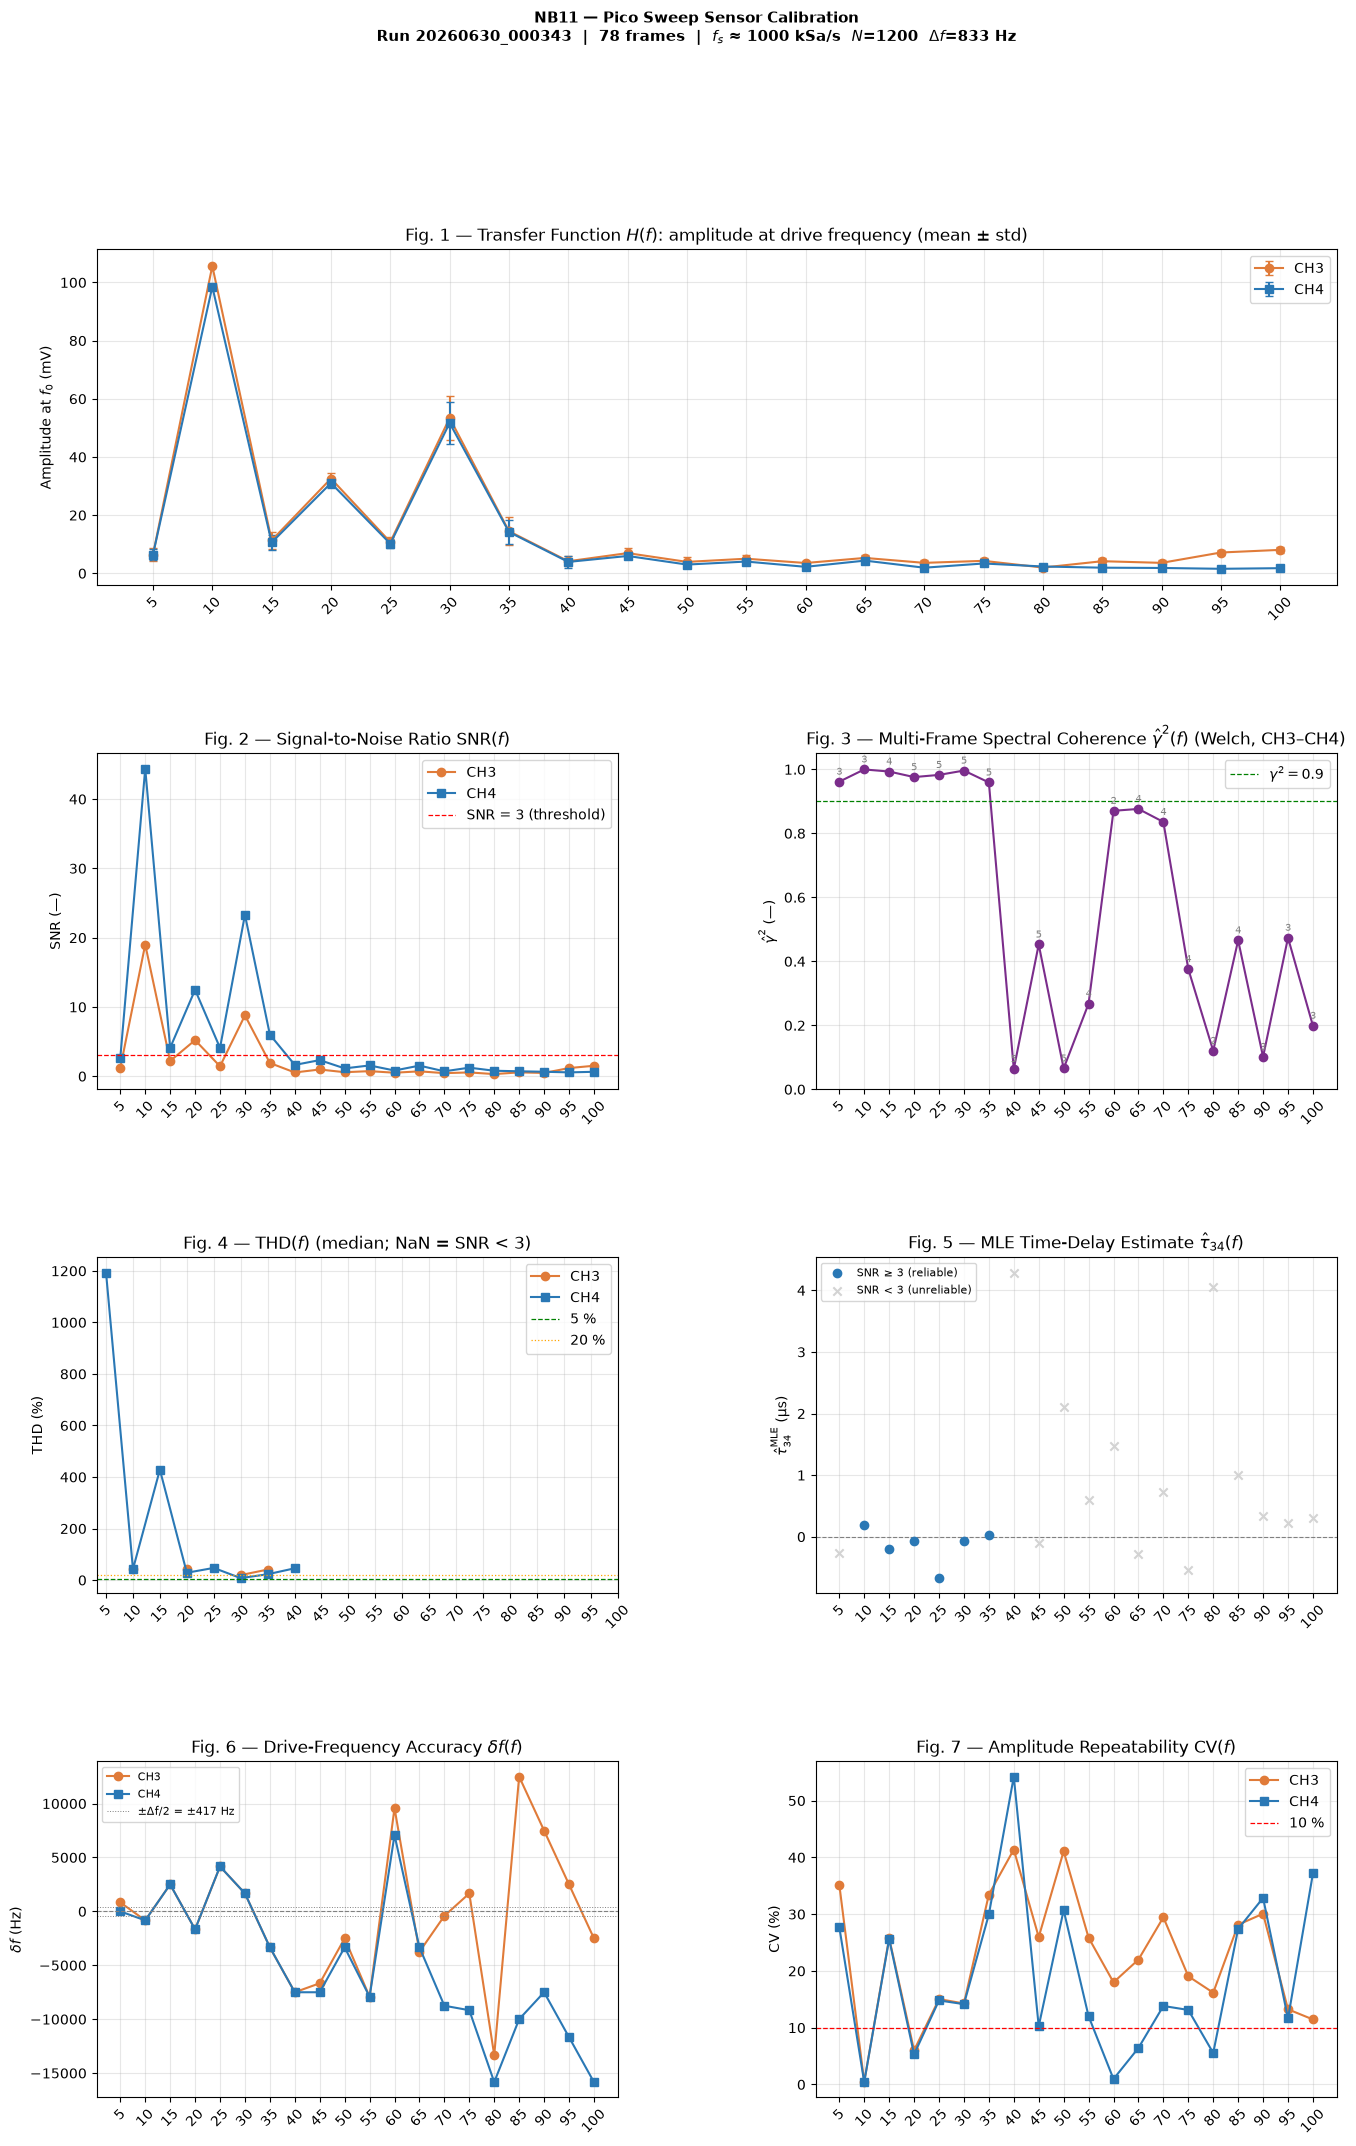

Figure saved: ../data/pico_sweep_calibration/20260630_000343/calibration_report.png


In [7]:
C3, C4 = '#E07B39', '#2A78B5'
fig = plt.figure(figsize=(16, 24))
gs  = gridspec.GridSpec(4, 2, figure=fig, hspace=0.50, wspace=0.38)

# Fig. 1 — H(f)
ax = fig.add_subplot(gs[0, :])
m3v = [stat('amp3_V',b,mean)*1e3 for b in bands]
m4v = [stat('amp4_V',b,mean)*1e3 for b in bands]
s3v = [stat('amp3_V',b,std)*1e3  for b in bands]
s4v = [stat('amp4_V',b,std)*1e3  for b in bands]
ax.errorbar(bx,m3v,yerr=s3v,fmt='o-',color=C3,capsize=3,label='CH3')
ax.errorbar(bx,m4v,yerr=s4v,fmt='s-',color=C4,capsize=3,label='CH4')
ax.set_ylabel('Amplitude at $f_0$ (mV)')
ax.set_title('Fig. 1 — Transfer Function $H(f)$: amplitude at drive frequency (mean ± std)')
ax.legend(); ax.grid(True,alpha=0.3)
ax.set_xticks(bx); ax.tick_params(axis='x',rotation=45)

# Fig. 2 — SNR
ax2 = fig.add_subplot(gs[1,0])
ax2.plot(bx,[stat('snr3',b,mean) for b in bands],'o-',color=C3,label='CH3')
ax2.plot(bx,[stat('snr4',b,mean) for b in bands],'s-',color=C4,label='CH4')
ax2.axhline(3,ls='--',color='red',lw=0.9,label='SNR = 3 (threshold)')
ax2.set_ylabel('SNR (—)'); ax2.set_title('Fig. 2 — Signal-to-Noise Ratio SNR$(f)$')
ax2.legend(); ax2.grid(True,alpha=0.3)
ax2.set_xticks(bx); ax2.tick_params(axis='x',rotation=45)

# Fig. 3 — Coherence
ax3 = fig.add_subplot(gs[1,1])
ax3.plot(bx,[coh_mf[b] for b in bands],'o-',color='#7B2D8B')
ax3.axhline(0.9,ls='--',color='green',lw=0.9,label='$\\gamma^2=0.9$')
ax3.set_ylim(0,1.05)
ax3.set_ylabel('$\\hat{\\gamma}^2$ (—)')
ax3.set_title('Fig. 3 — Multi-Frame Spectral Coherence $\\hat{\\gamma}^2(f)$ (Welch, CH3–CH4)')
for b,x in zip(bands,bx):
    ax3.annotate(str(N_frames[b]),(x,min(coh_mf[b],1.03)),
                 textcoords='offset points',xytext=(0,5),
                 ha='center',fontsize=7,color='gray')
ax3.legend(); ax3.grid(True,alpha=0.3)
ax3.set_xticks(bx); ax3.tick_params(axis='x',rotation=45)

# Fig. 4 — THD
ax4 = fig.add_subplot(gs[2,0])
ax4.plot(bx,[stat('thd3',b,med)*100 for b in bands],'o-',color=C3,label='CH3')
ax4.plot(bx,[stat('thd4',b,med)*100 for b in bands],'s-',color=C4,label='CH4')
ax4.axhline(5, ls='--',color='green', lw=0.9,label='5 %')
ax4.axhline(20,ls=':',color='orange',lw=0.9,label='20 %')
ax4.set_ylabel('THD (%)'); ax4.set_title('Fig. 4 — THD$(f)$ (median; NaN = SNR < 3)')
ax4.legend(); ax4.grid(True,alpha=0.3)
ax4.set_xticks(bx); ax4.tick_params(axis='x',rotation=45)

# Fig. 5 — MLE TDE
ax5 = fig.add_subplot(gs[2,1])
snr_ok = [stat('snr4',b,mean) >= 3 for b in bands]
tau_v  = [tau_mle[b] for b in bands]
ax5.scatter([bx[i] for i in range(len(bands)) if snr_ok[i]],
            [tau_v[i] for i in range(len(bands)) if snr_ok[i]],
            color=C4,marker='o',zorder=3,label='SNR ≥ 3 (reliable)')
ax5.scatter([bx[i] for i in range(len(bands)) if not snr_ok[i]],
            [tau_v[i] for i in range(len(bands)) if not snr_ok[i]],
            color='lightgray',marker='x',zorder=2,label='SNR < 3 (unreliable)')
ax5.axhline(0,ls='--',color='gray',lw=0.8)
ax5.set_ylabel('$\\hat{\\tau}_{34}^{\\mathrm{MLE}}$ (µs)')
ax5.set_title('Fig. 5 — MLE Time-Delay Estimate $\\hat{\\tau}_{34}(f)$')
ax5.legend(fontsize=8); ax5.grid(True,alpha=0.3)
ax5.set_xticks(bx); ax5.tick_params(axis='x',rotation=45)

# Fig. 6 — Frequency accuracy
ax6 = fig.add_subplot(gs[3,0])
fs_nom = records[0]['fs_hz'] if records else 1e6
n_nom  = records[0]['n_pts'] if records else 1200
df_res = fs_nom / n_nom
ax6.plot(bx,[stat('peak_f3_hz',b,med)-b for b in bands],'o-',color=C3,label='CH3')
ax6.plot(bx,[stat('peak_f4_hz',b,med)-b for b in bands],'s-',color=C4,label='CH4')
ax6.axhline(0,ls='--',color='gray',lw=0.8)
ax6.axhline( df_res/2,ls=':',color='gray',lw=0.7)
ax6.axhline(-df_res/2,ls=':',color='gray',lw=0.7,
            label=f'±Δf/2 = ±{df_res/2:.0f} Hz')
ax6.set_ylabel('$\\delta f$ (Hz)')
ax6.set_title('Fig. 6 — Drive-Frequency Accuracy $\\delta f(f)$')
ax6.legend(fontsize=8); ax6.grid(True,alpha=0.3)
ax6.set_xticks(bx); ax6.tick_params(axis='x',rotation=45)

# Fig. 7 — Repeatability
ax7 = fig.add_subplot(gs[3,1])
cv3 = [stat('amp3_V',b,std)/(stat('amp3_V',b,mean)+1e-12)*100 for b in bands]
cv4 = [stat('amp4_V',b,std)/(stat('amp4_V',b,mean)+1e-12)*100 for b in bands]
ax7.plot(bx,cv3,'o-',color=C3,label='CH3')
ax7.plot(bx,cv4,'s-',color=C4,label='CH4')
ax7.axhline(10,ls='--',color='red',lw=0.9,label='10 %')
ax7.set_ylabel('CV (%)'); ax7.set_title('Fig. 7 — Amplitude Repeatability CV$(f)$')
ax7.legend(); ax7.grid(True,alpha=0.3)
ax7.set_xticks(bx); ax7.tick_params(axis='x',rotation=45)

fig.suptitle(
    f'NB11 — Pico Sweep Sensor Calibration\n'
    f'Run {RUN_LOCAL}  |  {len(records)} frames  |  '
    f'$f_s$ ≈ {fs_nom/1e3:.0f} kSa/s  $N$={n_nom}  $\\Delta f$={df_res:.0f} Hz',
    fontsize=11, fontweight='bold')
plt.savefig(OUT/'calibration_report.png',dpi=150,bbox_inches='tight')
plt.show()
print(f'Figure saved: {OUT}/calibration_report.png')


## 9  Summary Table

All per-frame quantities: mean ± std.
$\hat{\gamma}^2$ and $\hat{\tau}_{34}^{\text{MLE}}$: single Welch estimate from all $N$ frames.
THD: median over SNR-valid frames (NaN if no valid frames).


In [8]:
hdr = (f'{"f0 [kHz]":>9} {"N":>3}  {"A3 [mV]":>13}  {"A4 [mV]":>13}  '
       f'{"SNR4":>6}  {"γ²":>7}  {"THD4 [%]":>9}  '
       f'{"τ_MLE [µs]":>12}  {"CV4 [%]":>8}  {"δf4 [Hz]":>9}')
print(hdr)
print('-' * len(hdr))
for b in bands:
    a3m = stat('amp3_V',b,mean)*1e3; a3s = stat('amp3_V',b,std)*1e3
    a4m = stat('amp4_V',b,mean)*1e3; a4s = stat('amp4_V',b,std)*1e3
    s4  = stat('snr4',b,mean)
    g2  = coh_mf[b]
    t4  = stat('thd4',b,med)
    t4s = f'{t4*100:.1f}' if t4==t4 else 'NaN'
    tau = tau_mle[b]
    cv4 = stat('amp4_V',b,std)/(stat('amp4_V',b,mean)+1e-12)*100
    df4 = stat('peak_f4_hz',b,med) - b
    print(f'{b/1e3:>8.1f}  {N_frames[b]:>3}  '
          f'{a3m:>6.3f}±{a3s:.3f}  {a4m:>6.3f}±{a4s:.3f}  '
          f'{s4:>6.1f}  {g2:>7.4f}  {t4s:>9}  '
          f'{tau:>+12.3f}  {cv4:>8.1f}  {df4:>+9.0f}')


 f0 [kHz]   N        A3 [mV]        A4 [mV]    SNR4       γ²   THD4 [%]    τ_MLE [µs]   CV4 [%]   δf4 [Hz]
----------------------------------------------------------------------------------------------------------
     5.0    3   6.436±2.266   6.418±1.780     2.7   0.9615     1193.2        -0.258      27.7         +0
    10.0    3  105.658±0.475  98.551±0.414    44.4   0.9998       42.7        +0.193       0.4       -833
    15.0    4  11.324±2.921  10.601±2.714     4.1   0.9932      428.5        -0.201      25.6      +2500
    20.0    5  32.580±1.957  31.037±1.648    12.5   0.9759       28.5        -0.062       5.3      -1667
    25.0    5  10.759±1.618  10.184±1.508     4.1   0.9827       47.4        -0.671      14.8      +4167
    30.0    5  53.401±7.621  51.700±7.315    23.3   0.9963        7.9        -0.077      14.1      +1667
    35.0    5  14.493±4.849  14.222±4.260     6.0   0.9591       22.7        +0.023      30.0      -3333
    40.0    5   4.155±1.719   3.925±2.128     1.6 